### K-means: perfiis de participantes do ENEM

In [2]:
import matplotlib.pyplot as plt
import numpy as np
from statstech.cluster import KMeans
from statstech.preprocessing import StandardScaler

from analysis.config import SEED, STYLE
from analysis.io import load_dataset
from analysis.report import save_figure, save_table

plt.style.use(STYLE)

In [4]:
dados = load_dataset('enem')

X_train = dados['X_train']
y_train = dados['y_train']
nomes = list(dados['feature_names'])

# Variaveis que descrevem a condição socioeconomica
COLUNAS = [
  'log_income_per_capita',
  'asset_index_1',
  'father_education',
  'mother_education',
]
idx = [nomes.index(c) for c in COLUNAS]

# Quem marcou 'nao sei' na escolaridade dos pais
sem_info = (
  (X_train[:, nomes.index('father_education_unknown')] == 1) | (X_train[:, nomes.index('mother_education_unknown')] == 1)
)

X = X_train[~sem_info][:, idx]
y = y_train[~sem_info]

print('Treino total:', X_train.shape[0])
print('Excluídos (não sei):', sem_info.sum())
print('Usados no K-means:', X.shape)

Treino total: 38347
Excluídos (não sei): 4548
Usados no K-means: (33799, 4)


2 81661.7 iterações: 15
3 63790.2 iterações: 9
4 49742.4 iterações: 48
5 43313.7 iterações: 21
6 37799.1 iterações: 20
7 33862.4 iterações: 12
8 31805.4 iterações: 16


PosixPath('/home/mclaracarvalho/statstech-analise/results/figures/enem_kmeans_inercia.png')

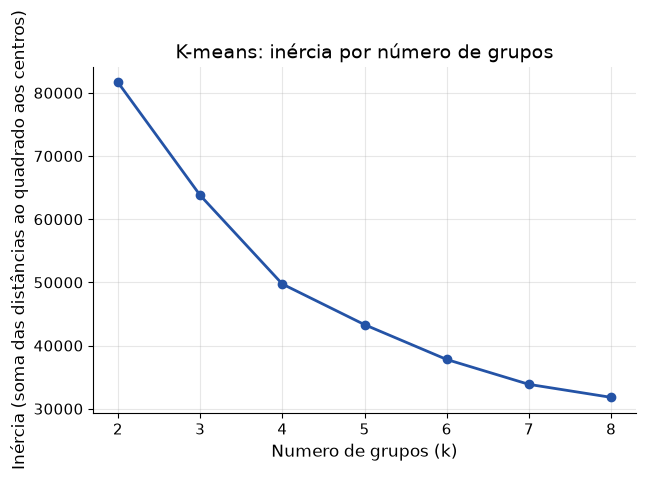

In [7]:
Xp = StandardScaler().fit_transform(X)

ks = list(range(2, 9))
inercias = []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Xp)
    inercias.append(km.inertia_)
    print(k, round(km.inertia_, 1), "iterações:", km.n_iter_)

fig, ax = plt.subplots()
ax.plot(ks, inercias, marker="o")
ax.set_xlabel("Numero de grupos (k)")
ax.set_ylabel("Inércia (soma das distâncias ao quadrado aos centros)")
ax.set_title("K-means: inércia por número de grupos")
save_figure(fig, "enem_kmeans_inercia")

In [8]:
K = 4
km = KMeans(n_clusters=K, n_init=10, random_state=SEED).fit(Xp)

linhas = []
for g in range(K):
    mask = km.labels_ == g
    linha = {
        "n": int(mask.sum()),
        "pct": round(100 * float(mask.mean()), 1),
        "nota_media": round(float(y[mask].mean()), 1),
    }
    for j, c in enumerate(COLUNAS):
        linha[c] = round(float(X[mask, j].mean()), 2)
    linhas.append(linha)

# Ordena do grupo de menor para o de maior nota média
linhas.sort(key=lambda d: d["nota_media"])
for i, linha in enumerate(linhas, start=1):
    linha["grupo"] = i
    print(linha)

save_table(linhas, "enem_kmeans_perfis")

{'n': 1606, 'pct': 4.8, 'nota_media': 490.1, 'log_income_per_capita': 0.0, 'asset_index_1': -2.4, 'father_education': 2.12, 'mother_education': 2.62, 'grupo': 1}
{'n': 8834, 'pct': 26.1, 'nota_media': 508.0, 'log_income_per_capita': 5.63, 'asset_index_1': -1.5, 'father_education': 1.63, 'mother_education': 2.29, 'grupo': 2}
{'n': 15318, 'pct': 45.3, 'nota_media': 546.3, 'log_income_per_capita': 6.31, 'asset_index_1': -0.41, 'father_education': 3.7, 'mother_education': 4.15, 'grupo': 3}
{'n': 8041, 'pct': 23.8, 'nota_media': 612.4, 'log_income_per_capita': 7.71, 'asset_index_1': 3.33, 'father_education': 4.87, 'mother_education': 5.17, 'grupo': 4}


PosixPath('/home/mclaracarvalho/statstech-analise/results/tables/enem_kmeans_perfis.csv')